<div dir="rtl">

# کارگاه جلسه ۲۰ — مبانی طبقه‌بندی و k-NN

این دفترچه ابزارهایی را تمرین می‌کند که در جزوه نیامده‌اند. هر بخش مستقل است. نوشتن این کدها در امتحان پرسیده نمی‌شود.

1. توضیح یک پیش‌بینی با نزدیک‌ترین همسایه‌ها
2. تمرین عملی کلاس: گل زنبق و پاسخ‌ها

</div>

<div dir="rtl">

## ۱. توضیح یک پیش‌بینی با نزدیک‌ترین همسایه‌ها

مزیت k-NN این است که هر پیش‌بینی را می‌توان با **خود نمونه‌های آموزش** توضیح داد. متد `kneighbors` نزدیک‌ترین مسافران آموزش به یک مسافر آزمون را برمی‌گرداند؛ چون مدل داخل Pipeline است، ابتدا مسافر را با همان پیش‌پردازش (`model[0].transform`) تبدیل می‌کنیم. فاصله‌ها در فضای استانداردشده‌اند.

</div>

In [1]:
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier

titanic = sns.load_dataset("titanic")
num = ["age", "fare", "sibsp", "parch", "pclass"]
cat = ["sex", "embarked"]
X_train, X_test, y_train, y_test = train_test_split(titanic[num + cat], titanic["survived"],
                                                    test_size=0.2, stratify=titanic["survived"],
                                                    random_state=42)
preprocess = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                          OneHotEncoder(handle_unknown="ignore")), cat)])
model = make_pipeline(preprocess, KNeighborsClassifier(n_neighbors=17)).fit(X_train, y_train)

# Explain one prediction: who are the nearest training passengers of a test passenger?
passenger = X_test.iloc[[0]]
dist, idx = model[-1].kneighbors(model[0].transform(passenger), n_neighbors=5)
neighbours = X_train.iloc[idx[0]].assign(survived=y_train.iloc[idx[0]].values, distance=dist[0].round(2))
print(passenger.to_string())
print(f"P(survived)={model.predict_proba(passenger)[0, 1]:.2f}")
print(neighbours.to_string())

      age   fare  sibsp  parch  pclass   sex embarked
565  24.0  24.15      2      0       3  male        S
P(survived)=0.18
      age     fare  sibsp  parch  pclass   sex embarked  survived  distance
69   26.0   8.6625      2      0       3  male        S         0      0.36
392  28.0   7.9250      2      0       3  male        S         0      0.46
267  25.0   7.7750      1      0       3  male        S         1      1.01
403  28.0  15.8500      1      0       3  male        S         0      1.01
451   NaN  19.9667      1      0       3  male        S         0      1.01


<div dir="rtl">

## ۲. تمرین عملی کلاس (۲۵ دقیقه)

داده گل زنبق (`load_iris`) را بارگذاری و با `test_size=0.3`، `stratify=y` و `random_state=42` تقسیم کنید.

1. فقط با دو ویژگی **طول و عرض گلبرگ** یک Pipeline شامل `StandardScaler` و `KNeighborsClassifier` بسازید.
2. برای k برابر ۱، ۱۵ و ۵۰ صحت آموزش و آزمون را گزارش و مرز تصمیم هر سه را رسم کنید.
3. همین کار را با دو ویژگی **کاسبرگ** تکرار کنید. کدام جفت ویژگی کلاس‌ها را بهتر جدا می‌کند؟
4. با هر چهار ویژگی، بهترین k را با `GridSearchCV` (اعتبارسنجی ۵ بخشی طبقه‌بندی‌شده با بر زدن و `random_state=42`) پیدا کنید و صحت آزمون را گزارش کنید. کدام گونه‌ها با هم اشتباه گرفته می‌شوند؟ (راهنما: `pd.crosstab`)

</div>

In [2]:
# Write your solution here

<div dir="rtl">

### پاسخ تمرین

</div>

petal k= 1  train=0.990  test=1.000
petal k=15  train=0.981  test=0.911


petal k=50  train=0.981  test=0.911


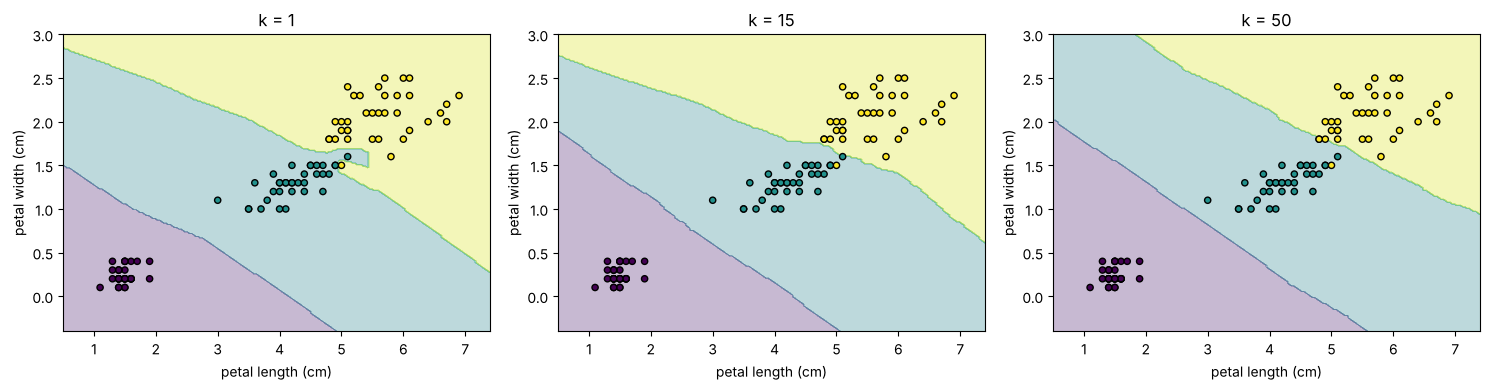

sepal k= 1  train=0.943  test=0.711
sepal k=15  train=0.829  test=0.667
sepal k=50  train=0.829  test=0.689


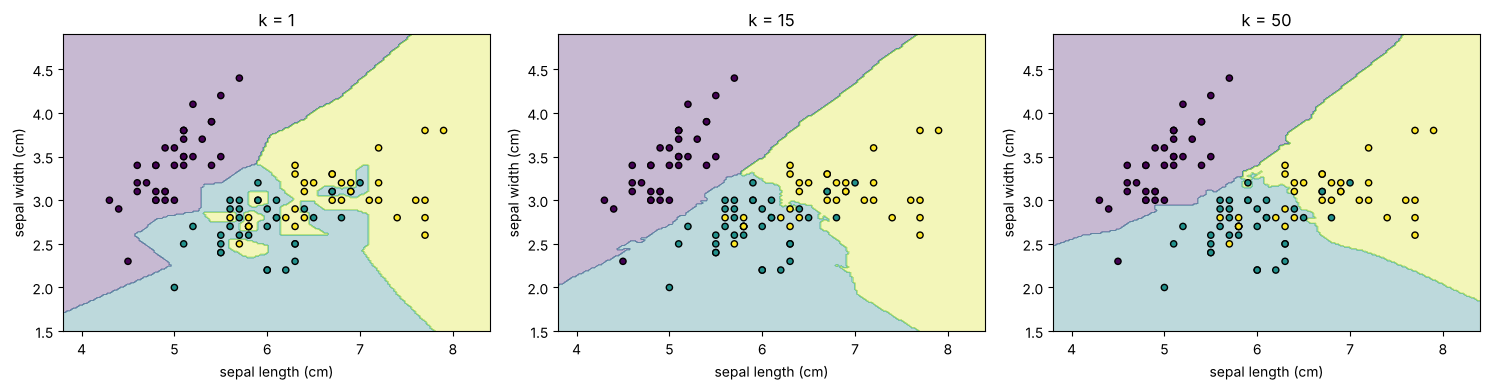

best={'kneighborsclassifier__n_neighbors': 8}  CV accuracy=0.971  test accuracy=0.911
predicted   setosa  versicolor  virginica
actual                                   
setosa          15           0          0
versicolor       0          15          0
virginica        0           4         11


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

for pair in [["petal length (cm)", "petal width (cm)"], ["sepal length (cm)", "sepal width (cm)"]]:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, k in zip(axes, [1, 15, 50]):
        model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(X_train[pair], y_train)
        print(f"{pair[0].split()[0]:5s} k={k:2d}  train={model.score(X_train[pair], y_train):.3f}  "
              f"test={model.score(X_test[pair], y_test):.3f}")
        x0, x1 = X[pair[0]], X[pair[1]]
        xx, yy = np.meshgrid(np.linspace(x0.min() - 0.5, x0.max() + 0.5, 200),
                             np.linspace(x1.min() - 0.5, x1.max() + 0.5, 200))
        zz = model.predict(pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=pair)).reshape(xx.shape)
        ax.contourf(xx, yy, zz, alpha=0.3, cmap="viridis")
        ax.scatter(X_train[pair[0]], X_train[pair[1]], c=y_train, cmap="viridis", edgecolor="k", s=20)
        ax.set(title=f"k = {k}", xlabel=pair[0], ylabel=pair[1])
    plt.tight_layout()
    plt.show()

gs = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()),
                  {"kneighborsclassifier__n_neighbors": range(1, 31)},
                  cv=StratifiedKFold(5, shuffle=True, random_state=42)).fit(X_train, y_train)
print(f"best={gs.best_params_}  CV accuracy={gs.best_score_:.3f}  test accuracy={gs.score(X_test, y_test):.3f}")
names = np.array(iris.target_names)
print(pd.crosstab(names[y_test], names[gs.predict(X_test)], rownames=["actual"], colnames=["predicted"]))

<div dir="rtl">

### پاسخ‌های کلیدی

- با ویژگی‌های گلبرگ، صحت آزمون برای k برابر ۱، ۱۵ و ۵۰ به ترتیب ۱.۰۰۰، ۰.۹۱۱ و ۰.۹۱۱ است. صحت آموزش ۰.۹۹۰ برای k برابر ۱ (نه ۱۰۰ درصد) به دلیل گل‌های **تکراری** با برچسب متفاوت است.
- با ویژگی‌های کاسبرگ صحت آزمون فقط ۰.۷۱۱، ۰.۶۶۷ و ۰.۶۸۹ است. ویژگی‌های **گلبرگ** کلاس‌ها را بسیار بهتر جدا می‌کنند؛ انتخاب ویژگی خوب از انتخاب k مهم‌تر است.
- با چهار ویژگی، بهترین k برابر **۸** با صحت اعتبارسنجی ۰.۹۷۱ و صحت آزمون ۰.۹۱۱ است. هر چهار خطا گل‌های **virginica** هستند که versicolor پیش‌بینی شده‌اند؛ setosa هیچ خطایی ندارد.

</div>